In [6]:
import sys
!{sys.executable} -m pip install openpyxl

  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]



In [16]:
import sys
!{sys.executable} -m pip install textblob

   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 625.0/625.0 kB 5.8 MB/s  0:00:00
   ---------------------------------------- 0.0/1.6 MB ? eta -:--:--
   --------------------------------- ------ 1.3/1.6 MB 6.7 MB/s eta 0:00:01
   ---------------------------------------- 1.6/1.6 MB 6.4 MB/s  0:00:00

   -------------------- ------------------- 2/4 [nltk]
   -------------------- ------------------- 2/4 [nltk]
   -------------------- ------------------- 2/4 [nltk]
   -------------------- ------------------- 2/4 [nltk]
   -------------------- ------------------- 2/4 [nltk]
   -------------------- ------------------- 2/4 [nltk]
   ---------------------------------------- 4/4 [textblob]



In [17]:
import pandas as pd
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt

from textblob import TextBlob
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [7]:
import pandas as pd

df = pd.read_excel(r'C:\Users\sanka\OneDrive\Documents\Data Mining\airline-analysis\data\MGT0000_ITAG7105_new_dataset_final (1).xlsx')

df.head()

,ID,Airline Name,Overall_Rating,Review Title,Country,Review Date,Verified,Review,Type Of Traveller,Seat Type,...,Date Flown,Seat Comfort,Cabin Staff Service,Food & Beverages,Inflight Entertainment,Ground Service,Wifi & Connectivity,Value For Money,Recommended,Aircraft
0,0,AB Aviation,8,"""pretty decent airline""",Netherlands,11th November 2019,True,✅Trip Verified| Moroni to Moheli. Turned out ...,Solo Leisure,Economy Class,...,November 2019,4.0,5.0,4.0,NaN,4.0,NaN,3.0,yes,NaN
1,1,AB Aviation,3,"""Not a good airline""",United Kingdom,25th June 2019,True,✅Trip Verified| Moroni to Anjouan. It is a ver...,Solo Leisure,Economy Class,...,June 2019,2.0,2.0,1.0,NaN,1.0,NaN,2.0,no,E120
2,2,AB Aviation,3,"""flight was fortunately short""",United Kingdom,25th June 2019,True,✅Trip Verified| Anjouan to Dzaoudzi. A very s...,Solo Leisure,Economy Class,...,June 2019,2.0,1.0,1.0,NaN,1.0,NaN,2.0,no,Embraer E120
3,3,Adria Airways,2,"""it ruined our last days of holidays""",Netherlands,24th September 2019,True,✅Trip Verified| Do not book a flight with this...,Couple Leisure,Economy Class,...,September 2019,1.0,1.0,1.0,1.0,1.0,1.0,1.0,no,NaN
4,4,Adria Airways,2,"""Had very bad experience""",Austria,17th September 2019,True,✅Trip Verified| Had very bad experience with ...,Couple Leisure,Economy Class,...,September 2019,1.0,1.0,1.0,1.0,1.0,1.0,1.0,no,CR 900


In [8]:
df.columns

Index(['ID', 'Airline Name', 'Overall_Rating', 'Review Title', 'Country',
       'Review Date', 'Verified', 'Review', 'Type Of Traveller', 'Seat Type',
       'Route', 'Date Flown', 'Seat Comfort', 'Cabin Staff Service',
       'Food & Beverages', 'Inflight Entertainment', 'Ground Service',
       'Wifi & Connectivity', 'Value For Money', 'Recommended', 'Aircraft'],
      dtype='object')

In [20]:
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df['Recommended'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6178 entries, 0 to 6177
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      6178 non-null   object 
 1   Airline Name            6178 non-null   object 
 2   Overall_Rating          6178 non-null   float64
 3   Review Title            6178 non-null   object 
 4   Country                 6178 non-null   object 
 5   Review Date             6178 non-null   object 
 6   Verified                6178 non-null   bool   
 7   Review                  6178 non-null   object 
 8   Type Of Traveller       6176 non-null   object 
 9   Seat Type               6178 non-null   object 
 10  Route                   6169 non-null   object 
 11  Date Flown              6176 non-null   object 
 12  Seat Comfort            6178 non-null   float64
 13  Cabin Staff Service     6178 non-null   float64
 14  Food & Beverages        6178 non-null   

In [21]:
# Fix Overall Rating
df['Overall_Rating'] = pd.to_numeric(df['Overall_Rating'], errors='coerce')

# Fix target
df['Recommended'] = df['Recommended'].str.lower()
df['recommend_binary'] = df['Recommended'].map({'yes':1, 'no':0})

# Missing indicators (IMPORTANT)
df['has_wifi'] = df['Wifi & Connectivity'].notnull().astype(int)
df['has_entertainment'] = df['Inflight Entertainment'].notnull().astype(int)

# Fill missing numerical values
df.fillna(df.median(numeric_only=True), inplace=True)

In [22]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'trip verified', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    return text

df['clean_review'] = df['Review'].apply(clean_text)

# Sentiment score
df['sentiment'] = df['clean_review'].apply(lambda x: TextBlob(x).sentiment.polarity)

In [23]:
# Value Gap (Expectation vs Value mismatch)
df['value_gap'] = df['Overall_Rating'] - df['Value For Money']

# Service Consistency (experience variability)
ratings = [
    'Seat Comfort',
    'Cabin Staff Service',
    'Food & Beverages',
    'Ground Service'
]

df['service_consistency'] = df[ratings].std(axis=1)

In [36]:
df.groupby('recommend_binary')[['value_gap','service_consistency']].mean()

,value_gap,service_consistency
recommend_binary,,
0,1.660902,0.688300
1,2.187994,0.740871


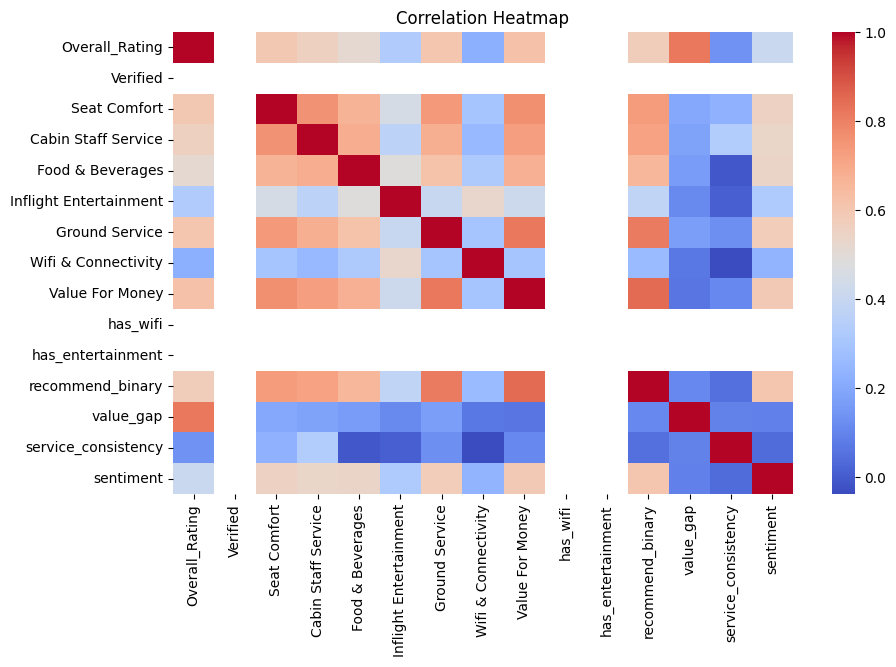

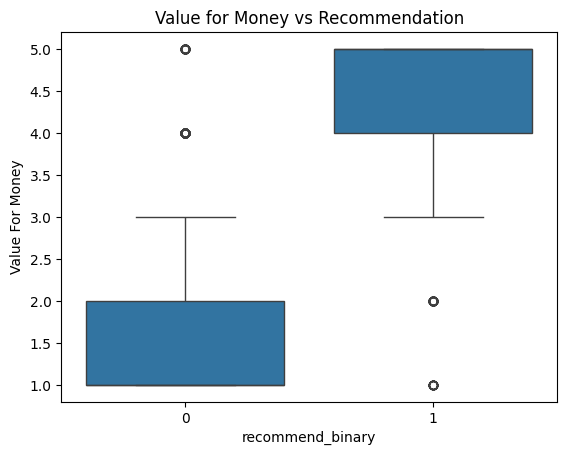

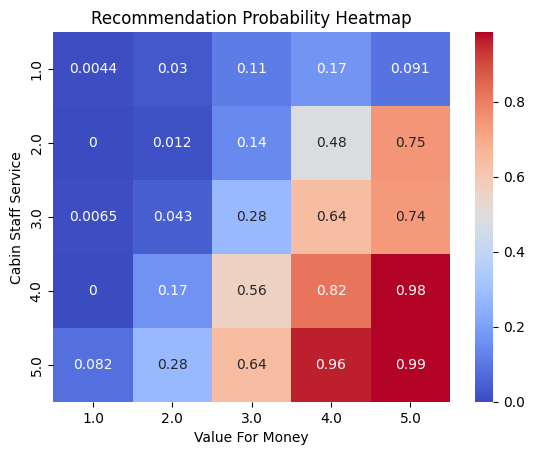

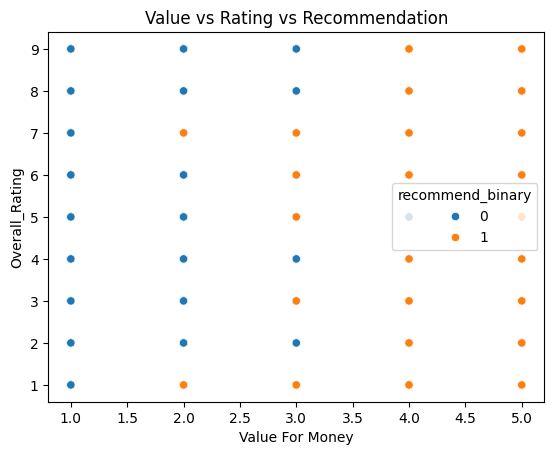

In [ ]:
# Correlation Heatmap
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

# Value vs Recommendation
sns.boxplot(x='recommend_binary', y='Value For Money', data=df)
plt.title("Value for Money vs Recommendation")
plt.show()

# Custom Heatmap (VERY IMPORTANT)
pivot = df.pivot_table(values='recommend_binary', index='Cabin Staff Service', columns='Value For Money')

sns.heatmap(pivot, annot=True, cmap='coolwarm')
plt.title("Recommendation Probability Heatmap")
plt.show()

# Scatter plot (extra insight)
sns.scatterplot(x=df['Value For Money'], 
                y=df['Overall_Rating'], 
                hue=df['recommend_binary'])
plt.title("Value vs Rating vs Recommendation")
plt.show()

In [25]:
contradictions = df[(df['sentiment'] > 0.3) & (df['recommend_binary'] == 0)]

print("Contradictory cases:")
contradictions[['Review', 'sentiment']].head(10)

Contradictory cases:


,Review,sentiment
82,✅Trip Verified| I booked London - Mexico Cit...,0.383333
133,"✅Trip Verified| Everything was perfect, but n...",0.345833
367,✅Trip Verified| Not a reliable flight. Delaye...,0.500000
519,✅Trip Verified| Seat Comfort was excellent. ...,0.346481
655,"✅Trip Verified| Clean plane, but no water ser...",0.523333
677,✅Trip Verified| The flight was canceled. It'...,0.392857
900,✅Trip Verified| This was a perfect flight. It...,0.553810
985,✅Trip Verified| I was booked to fly but travel...,0.650000
993,✅Trip Verified| Sofia to Lisbon. This four ho...,0.420000
1139,✅Trip Verified| This was a perfect flight. It...,0.553810


In [39]:
df.groupby('recommend_binary')['sentiment'].mean()

recommend_binary
0   -0.042992
1    0.254490
Name: sentiment, dtype: float64

In [26]:
df['Review Date'] = pd.to_datetime(df['Review Date'], errors='coerce')

df = df.sort_values('Review Date')

train = df.iloc[:int(0.8 * len(df))]
test = df.iloc[int(0.8 * len(df)):]

In [37]:
print("Train period:", train['Review Date'].min(), "to", train['Review Date'].max())
print("Test period:", test['Review Date'].min(), "to", test['Review Date'].max())

Train period: 2017-11-18 00:00:00 to 2025-04-20 00:00:00
Test period: NaT to NaT


In [27]:
features = [
    'Overall_Rating',
    'Value For Money',
    'Cabin Staff Service',
    'sentiment',
    'has_wifi',
    'value_gap',
    'service_consistency'
]

X_train = train[features]
y_train = train['recommend_binary']

X_test = test[features]
y_test = test['recommend_binary']

In [28]:
# Logistic Regression
log_model = LogisticRegression(max_iter=1000, class_weight='balanced')
log_model.fit(X_train, y_train)

# Random Forest (tuned)
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,10
,min_samples_split,5
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [29]:
# Logistic
pred_log = log_model.predict(X_test)

print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, pred_log))
print(classification_report(y_test, pred_log))

# Random Forest
pred_rf = rf_model.predict(X_test)

print("\nRandom Forest")
print("Accuracy:", accuracy_score(y_test, pred_rf))
print(classification_report(y_test, pred_rf))

Logistic Regression
Accuracy: 0.9288025889967637
              precision    recall  f1-score   support

           0       0.95      0.94      0.95       843
           1       0.88      0.90      0.89       393

    accuracy                           0.93      1236
   macro avg       0.92      0.92      0.92      1236
weighted avg       0.93      0.93      0.93      1236


Random Forest
Accuracy: 0.936084142394822
              precision    recall  f1-score   support

           0       0.94      0.97      0.95       843
           1       0.92      0.87      0.90       393

    accuracy                           0.94      1236
   macro avg       0.93      0.92      0.93      1236
weighted avg       0.94      0.94      0.94      1236



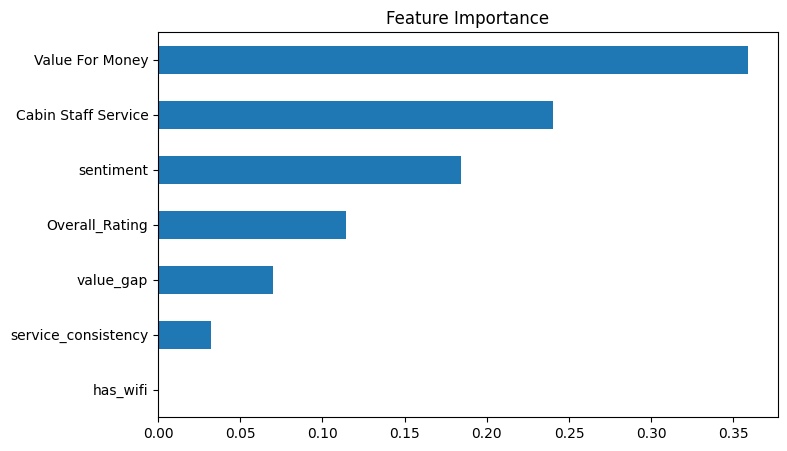

In [30]:
importance = pd.Series(rf_model.feature_importances_, index=features)
importance.sort_values().plot(kind='barh', figsize=(8,5))
plt.title("Feature Importance")
plt.show()

In [33]:
pd.DataFrame({
    'feature': features,
    'importance': rf_model.feature_importances_
}).sort_values(by='importance', ascending=False)

,feature,importance
1,Value For Money,0.359189
2,Cabin Staff Service,0.239996
3,sentiment,0.184406
0,Overall_Rating,0.114460
5,value_gap,0.069844
6,service_consistency,0.032106
4,has_wifi,0.000000


In [38]:
high_gap_cases = df[(df['value_gap'] > 3) & (df['recommend_binary'] == 0)]

print("Number of high value gap dissatisfied customers:", len(high_gap_cases))

high_gap_cases[['Overall_Rating','Value For Money','value_gap']].head()

Number of high value gap dissatisfied customers: 495


,Overall_Rating,Value For Money,value_gap
105,6.0,1.0,5.0
4994,9.0,4.0,5.0
5376,7.0,3.0,4.0
6153,8.0,1.0,7.0
6152,8.0,1.0,7.0


In [34]:
error_df = X_test.copy()
error_df['actual'] = y_test.values
error_df['predicted'] = pred_rf

errors = error_df[error_df['actual'] != error_df['predicted']]

print("Number of misclassified cases:", len(errors))
errors.describe()

Number of misclassified cases: 79


,Overall_Rating,Value For Money,Cabin Staff Service,sentiment,has_wifi,value_gap,service_consistency,actual,predicted
count,79.000000,79.000000,79.000000,79.000000,79.0,79.000000,79.000000,79.000000,79.000000
mean,4.430380,3.088608,3.341772,0.112268,1.0,1.341772,1.032826,0.632911,0.367089
std,2.600215,0.936303,1.175455,0.153308,0.0,2.740420,0.425848,0.485091,0.485091
min,1.000000,1.000000,1.000000,-0.215000,1.0,-4.000000,0.500000,0.000000,0.000000
25%,1.000000,3.000000,3.000000,0.023611,1.0,-1.000000,0.577350,0.000000,0.000000
50%,5.000000,3.000000,3.000000,0.101481,1.0,2.000000,0.957427,1.000000,0.000000
75%,6.000000,4.000000,4.000000,0.177990,1.0,3.000000,1.290994,1.000000,1.000000
max,9.000000,5.000000,5.000000,0.600000,1.0,7.000000,2.309401,1.000000,1.000000
